In [100]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [101]:
dataset = pd.read_csv('C:/Users/user/Downloads/classification data/Social_Network_Ads.csv').values

In [102]:
X = dataset[:,:-1]
y = dataset[:,-1]

In [103]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.25, random_state=42)
print(X_train.shape,X_test.shape,y_train.shape,y_test.shape)

(300, 2) (100, 2) (300,) (100,)


In [104]:
from sklearn.preprocessing import StandardScaler
sc = StandardScaler()
sc.fit(X_train)
Xsc_train = sc.transform(X_train)
Xsc_test = sc.transform(X_test)

In [105]:
from sklearn.linear_model import LogisticRegression
lr = LogisticRegression()
lr.fit(Xsc_train,y_train)

LogisticRegression()

In [106]:
y_pred = lr.predict(Xsc_test)

In [107]:
from sklearn.metrics import accuracy_score
acc = accuracy_score(y_test,y_pred)
print('accuracy:', acc*100)

accuracy: 86.0


In [108]:
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(y_test,y_pred)
tn = cm[0,0]
fp = cm[0,1]
fn = cm[1,0]
tp = cm[1,1]
print(cm)

[[61  2]
 [12 25]]


In [109]:
precision = tp / (tp+fp)
recall = tp/(tp+fn)
print('precision: ', precision*100)
print('recall: ',recall*100)

precision:  92.5925925925926
recall:  67.56756756756756


In [110]:
import sklearn
print(sklearn.__version__)

1.2.2


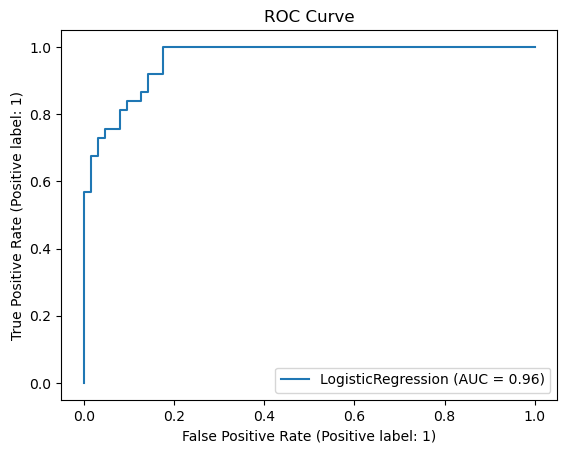

In [118]:
import matplotlib.pyplot as plt
from sklearn.metrics import RocCurveDisplay
disp = RocCurveDisplay.from_estimator(lr, Xsc_test, y_test)
plt.title('ROC Curve')
plt.show()

[0.         0.         0.         0.01587302 0.01587302 0.03174603
 0.03174603 0.04761905 0.04761905 0.07936508 0.07936508 0.0952381
 0.0952381  0.12698413 0.12698413 0.14285714 0.14285714 0.17460317
 0.17460317 1.        ]
[0.         0.02702703 0.56756757 0.56756757 0.67567568 0.67567568
 0.72972973 0.72972973 0.75675676 0.75675676 0.81081081 0.81081081
 0.83783784 0.83783784 0.86486486 0.86486486 0.91891892 0.91891892
 1.         1.        ]
[1.99245479 0.99245479 0.67304532 0.65928158 0.60077925 0.52340687
 0.499442   0.47622889 0.43689545 0.4064092  0.39913596 0.39883267
 0.39864316 0.37651609 0.36940803 0.36206399 0.31238682 0.29931439
 0.28019613 0.00208373]


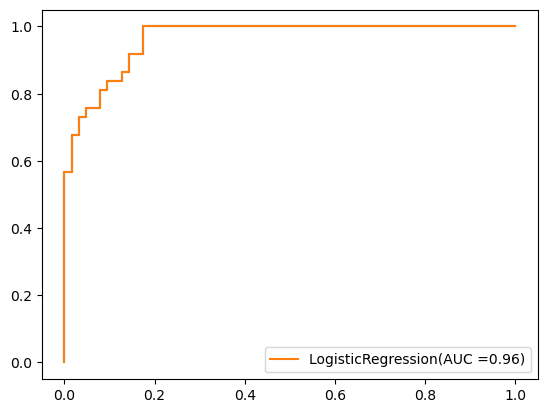

In [126]:
from sklearn.metrics import roc_curve, auc
y_pred_proba = lr.predict_proba(Xsc_test)
fpr,tpr,thresholds = roc_curve(y_test,y_pred_proba[:,1])
print(fpr)
print(tpr)
print(thresholds)
plt.plot(fpr,tpr)
lr_auc = auc(fpr,tpr)
label = 'LogisticRegression(AUC ={})'.format(round(lr_auc,2))
plt.plot(fpr,tpr,label = label)
plt.legend()
#roc_curve(y_test,y_pred_proba[:,1])